# Overview
In this notebook, we will build and train neural networks using [JAX](https://jax.readthedocs.io/). We will consider the following examples:

- MNIST dataset of handwritten digits
- Image reconstruction example

In [1]:
import jax
import jax.numpy as jnp
from jax import random, grad
import optax
from keras.datasets import mnist
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

## MNIST example of handwritten digits
The MNIST dataset is a standard machine learning benchmark containing 70,000 grayscale 28x28 pixel images of handwritten digits from zero to nine. 
It can be loaded directly through most deep learning libraries like `keras.datasets` or downloaded manually from [Yann LeCun's official website](http://yann.lecun.com/).

- 60,000 for training
- 10,000 for testing

In [2]:
# Load MNIST data
(x_train, y_train), (x_test, y_test) = mnist.load_data()

x_train = x_train.reshape(-1, 28*28) / 255.0
x_test  = x_test.reshape(-1, 28*28) / 255.0

y_train = jax.nn.one_hot(y_train, 10)
y_test  = jax.nn.one_hot(y_test, 10)

x_train = jnp.array(x_train)
y_train = jnp.array(y_train)
x_test  = jnp.array(x_test)
y_test  = jnp.array(y_test)

# Initialization 
def init_mnist_params(key):
    return {
        "W1": random.normal(key, (784, 128)) * 0.01,
        "b1": jnp.zeros(128),
        "W2": random.normal(key, (128, 10)) * 0.01,
        "b2": jnp.zeros(10),
    }

def mnist_forward(params, x):
    # can change activation function
    h = jax.nn.relu(x @ params["W1"] + params["b1"])
    return h @ params["W2"] + params["b2"]

def mnist_loss(params, x, y):
    logits = mnist_forward(params, x)
    return optax.softmax_cross_entropy(logits, y).mean()

# Training method (Gradient Descent)
    # can change lr and steps

def train_gd(params, lr=0.1, steps=20):
    losses = []
    for _ in range(steps):
        g = grad(mnist_loss)(params, x_train, y_train)
        params = jax.tree_util.tree_map(lambda w, dw: w - lr * dw, params, g)
        losses.append(mnist_loss(params, x_train, y_train))
    return params, jnp.array(losses)

def train_adam(params, lr=0.001, batch_size=128, steps=5000):
    opt = optax.adam(lr)
    opt_state = opt.init(params)

    losses = []
    key = random.PRNGKey(1)

    for _ in range(steps):
        key, sub = random.split(key)
        idx = random.choice(sub, len(x_train), shape=(batch_size,), replace=False)
        xb, yb = x_train[idx], y_train[idx]

        loss, grads = jax.value_and_grad(mnist_loss)(params, xb, yb)
        updates, opt_state = opt.update(grads, opt_state)
        params = optax.apply_updates(params, updates)

        losses.append(loss)

    return params, jnp.array(losses)

# Accuracy method
def mnist_accuracy(params, x, y):
    logits = mnist_forward(params, x)
    preds = jnp.argmax(logits, axis=1)
    labels = jnp.argmax(y, axis=1)
    correct = jnp.sum(preds == labels)
    accuracy = correct / x.shape[0]
    return int(correct), float(accuracy)

# Run training
mnist_params = init_mnist_params(random.PRNGKey(1))
gd_params, gd_train_loss = train_gd(mnist_params)
adam_params, adam_train_loss = train_adam(mnist_params)

# Compute accuracy
gd_correct, gd_acc = mnist_accuracy(gd_params, x_test, y_test)
adam_correct, adam_acc = mnist_accuracy(adam_params, x_test, y_test)

print(f"accuracy:   {gd_correct} / {len(x_test)}   ({gd_acc*100:.2f}%)")
print(f"Adam accuracy: {adam_correct} / {len(x_test)}   ({adam_acc*100:.2f}%)")

accuracy:   5531 / 10000   (55.31%)
Adam accuracy: 9766 / 10000   (97.66%)


[[ -9.470071  -10.052094    1.5150017   8.215043  -29.472883   -2.1717894
   -7.760845   -3.7340863  -2.7760618 -19.565912 ]]


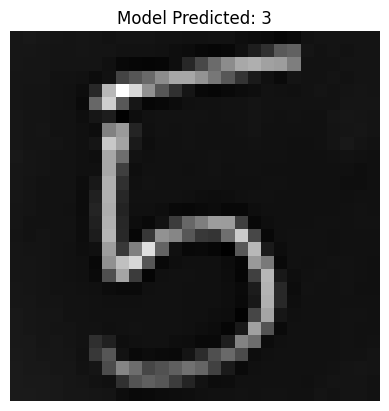

In [9]:

# 1. Load the image and convert to grayscale ('L' mode)
image_path = "5.jpg"  # Change this to your file's name
img = Image.open(image_path).convert('L')

# 2. Resize to 28x28 pixels
img = img.resize((28, 28))

# 3. Convert to a numpy array
img_array = np.array(img)

# 4. INVERT COLORS (Uncomment the line below if your image is dark ink on white paper)
img_array = 255 - img_array 
#img_array = np.where(img_array>130, 255, img_array)
# 5. Normalize pixel values to [0, 1] just like our training data
img_array = img_array / 255.0

# 6. Reshape to match the network's input shape: (1 sample, 784 pixels)
x_custom = img_array.reshape(1, 784)
x_custom = jnp.array(x_custom)

# 7. Predict using your trained gradient descent parameters (gd_params)
logits = mnist_forward(adam_params, x_custom)
#logits = mnist_forward(gd_params, x_custom)
prediction = jnp.argmax(logits, axis=1)[0]
print(logits)
# 8. Visualize what the model actually "sees" and its prediction
plt.imshow(img_array, cmap='gray')
plt.title(f"Model Predicted: {prediction}")
plt.axis('off')
plt.show()